# Churn rate analysis by Contract

This analysis preserves the original `Churn` column, creates a numeric `Churn_Encoded` column, and compares customer volume and churn rate across contract types. The table and charts below are generated directly from the loaded dataset; interpretations should be based on the displayed results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
import seaborn as sns

notebook_dir = Path.cwd()
if notebook_dir.name != "notebooks":
    notebook_dir = notebook_dir / "notebooks"
dataset_path = notebook_dir.parent / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(dataset_path)
df["Churn_Encoded"] = df["Churn"].map({"Yes": 1, "No": 0})

print(f"Dataset: {dataset_path}")
print(f"Original Churn column preserved: {'Churn' in df.columns}")
display(df[["Churn", "Churn_Encoded"]].head())

Dataset: d:\customer-churn-prediction\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Original Churn column preserved: True


,Churn,Churn_Encoded
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [ ]:
encoded_missing_count = df["Churn_Encoded"].isna().sum()
invalid_encoded_values = sorted(
    set(df["Churn_Encoded"].dropna().unique()) - {0, 1}
)

original_counts = df["Churn"].value_counts(dropna=False)
encoded_counts = df["Churn_Encoded"].value_counts(dropna=False)
encoding_counts_check = pd.DataFrame(
    {
        "Original Churn": [original_counts.get("No", 0), original_counts.get("Yes", 0)],
        "Encoded Churn": [encoded_counts.get(0, 0), encoded_counts.get(1, 0)],
    },
    index=["No / 0", "Yes / 1"],
)
encoding_counts_check["Match"] = (
    encoding_counts_check["Original Churn"]
    == encoding_counts_check["Encoded Churn"]
)

print(f"NaN trong Churn_Encoded: {encoded_missing_count}")
print(f"Giá trị ngoài 0 và 1: {invalid_encoded_values}")
display(encoding_counts_check)


In [2]:
contract_summary = (
    df.groupby("Contract")
    .agg(
        **{
            "Total customers": ("Churn_Encoded", "size"),
            "Churn count": ("Churn_Encoded", "sum"),
            "Churn rate (%)": ("Churn_Encoded", "mean"),
        }
    )
    .assign(**{"Churn rate (%)": lambda data: data["Churn rate (%)"] * 100})
    .sort_values("Churn rate (%)", ascending=False)
    .reset_index()
)

total_customers_table = contract_summary[["Contract", "Total customers"]]
churn_count_table = contract_summary[["Contract", "Churn count"]]
churn_rate_table = contract_summary[["Contract", "Churn rate (%)"]].copy()
churn_rate_table["Churn rate (%)"] = churn_rate_table["Churn rate (%)"].map(
    lambda rate: f"{rate:.2f}%"
)

print("1. Total Customers")
display(total_customers_table)
print("2. Churn Count")
display(churn_count_table)
print("3. Churn Rate (%)")
display(churn_rate_table)

,Contract,Total customers,Churn count,Churn rate (%)
0,Month-to-month,3875,1655,42.71%
1,One year,1473,166,11.27%
2,Two year,1695,48,2.83%


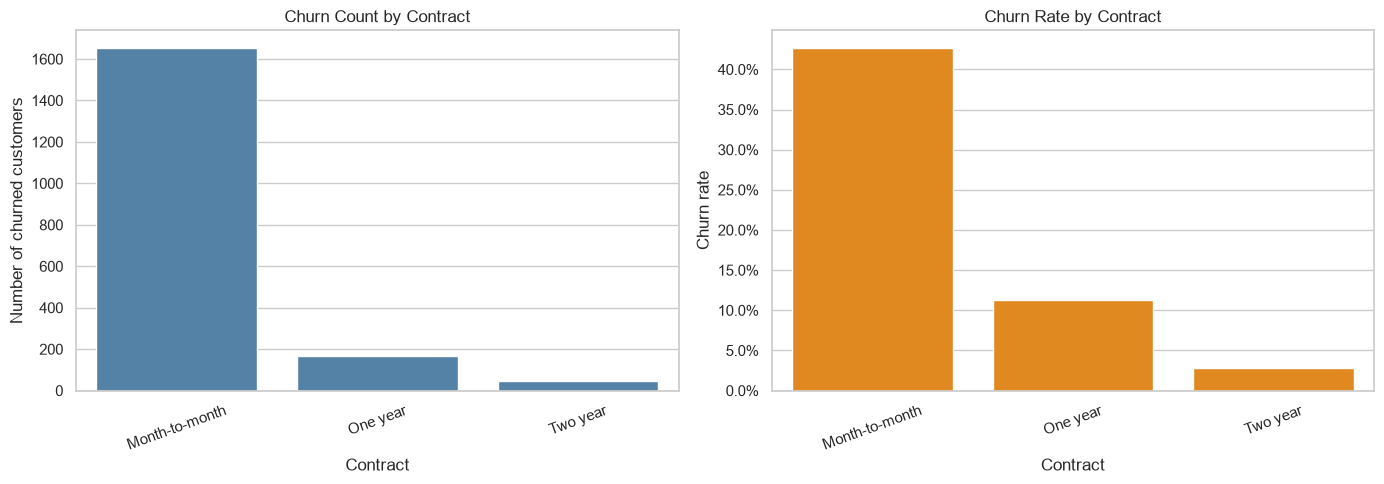

In [3]:
sns.set_theme(style="whitegrid")
contract_order = contract_summary["Contract"].tolist()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=contract_summary,
    x="Contract",
    y="Churn rate (%)",
    order=contract_order,
    color="darkorange",
)
plt.title("Churn Rate by Contract")
plt.xlabel("Contract")
plt.ylabel("Churn rate (%)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=100))
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## Churn Rate by Contract and Tenure

The following analysis groups customers by tenure and contract. It reports churn rates together with customer counts for every combination, so rates can be interpreted alongside their sample sizes. The results describe observed patterns only and do not establish causal relationships.

In [4]:
tenure_analysis = df.copy()
tenure_labels = [
    "0?12 months",
    "13?24 months",
    "25?48 months",
    "49?72 months",
]
tenure_analysis["tenure_group"] = pd.cut(
    tenure_analysis["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=tenure_labels,
    include_lowest=True,
)
tenure_analysis["tenure_group"] = tenure_analysis["tenure_group"].cat.reorder_categories(
    tenure_labels,
    ordered=True,
)

tenure_contract_summary = (
    tenure_analysis.groupby(["tenure_group", "Contract"], observed=False)
    .agg(
        **{
            "Customer count": ("Churn_Encoded", "size"),
            "Churn Rate (%)": ("Churn_Encoded", "mean"),
        }
    )
    .assign(**{"Churn Rate (%)": lambda data: data["Churn Rate (%)"] * 100})
    .reset_index()
)

churn_rate_pivot = tenure_contract_summary.pivot(
    index="tenure_group",
    columns="Contract",
    values="Churn Rate (%)",
).reindex(tenure_labels)

customer_count_pivot = tenure_contract_summary.pivot(
    index="tenure_group",
    columns="Contract",
    values="Customer count",
).reindex(tenure_labels)

print("Churn Rate (%) by Contract and Tenure")
display_churn_rate_pivot = churn_rate_pivot.map(
    lambda rate: f"{rate:.2f}%" if pd.notna(rate) else "NaN"
)
display(display_churn_rate_pivot)

print("Customer counts by Contract and Tenure")
display(customer_count_pivot.astype("Int64"))

Churn Rate (%) by Contract and Tenure


Contract,Month-to-month,One year,Two year
tenure_group,,,
0?12 months,51.35%,10.48%,0.00%
13?24 months,37.72%,8.12%,0.00%
25?48 months,32.92%,10.62%,2.19%
49?72 months,26.02%,12.93%,3.33%


Customer counts by Contract and Tenure


Contract,Month-to-month,One year,Two year
tenure_group,,,
0?12 months,1994,124,68
13?24 months,737,197,90
25?48 months,802,518,274
49?72 months,342,634,1263


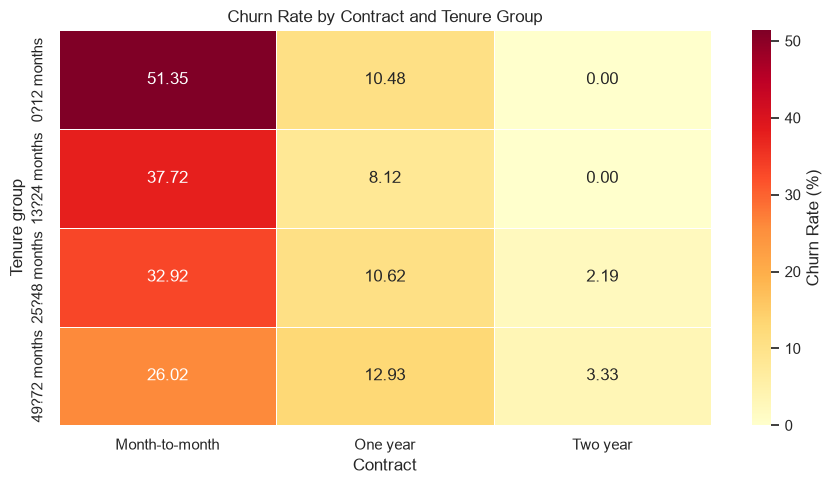

In [5]:
plt.figure(figsize=(9, 5))
sns.heatmap(
    churn_rate_pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
)
plt.title("Churn Rate by Contract and Tenure Group")
plt.xlabel("Contract")
plt.ylabel("Tenure group")
plt.tight_layout()
plt.show()

## MonthlyCharges distribution by Churn

This section compares the observed `MonthlyCharges` distributions for `Churn = 1` and `Churn = 0`. It reports descriptive statistics and visualizes the distributions without making causal claims.

In [6]:
monthly_charges_analysis = df[["MonthlyCharges", "Churn", "Churn_Encoded"]].copy()
monthly_charges_analysis = monthly_charges_analysis.dropna(subset=["MonthlyCharges", "Churn_Encoded"])

monthly_charges_stats = (
    monthly_charges_analysis.groupby("Churn_Encoded")["MonthlyCharges"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        q1=lambda values: values.quantile(0.25),
        q3=lambda values: values.quantile(0.75),
    )
    .rename(index={0: "Churn = 0", 1: "Churn = 1"})
)

print("MonthlyCharges descriptive statistics by Churn")
display(monthly_charges_stats.round(2))

mean_difference = monthly_charges_stats.loc["Churn = 1", "mean"] - monthly_charges_stats.loc["Churn = 0", "mean"]
median_difference = monthly_charges_stats.loc["Churn = 1", "median"] - monthly_charges_stats.loc["Churn = 0", "median"]
print(f"Observed mean difference (Churn = 1 minus Churn = 0): {mean_difference:.2f}")
print(f"Observed median difference (Churn = 1 minus Churn = 0): {median_difference:.2f}")
print("These are descriptive differences in this dataset and do not establish causation.")

MonthlyCharges descriptive statistics by Churn


,count,mean,median,std,q1,q3
Churn_Encoded,,,,,,
Churn = 0,5174,61.27,64.43,31.09,25.10,88.4
Churn = 1,1869,74.44,79.65,24.67,56.15,94.2


Observed mean difference (Churn = 1 minus Churn = 0): 13.18
Observed median difference (Churn = 1 minus Churn = 0): 15.22
These are descriptive differences in this dataset and do not establish causation.


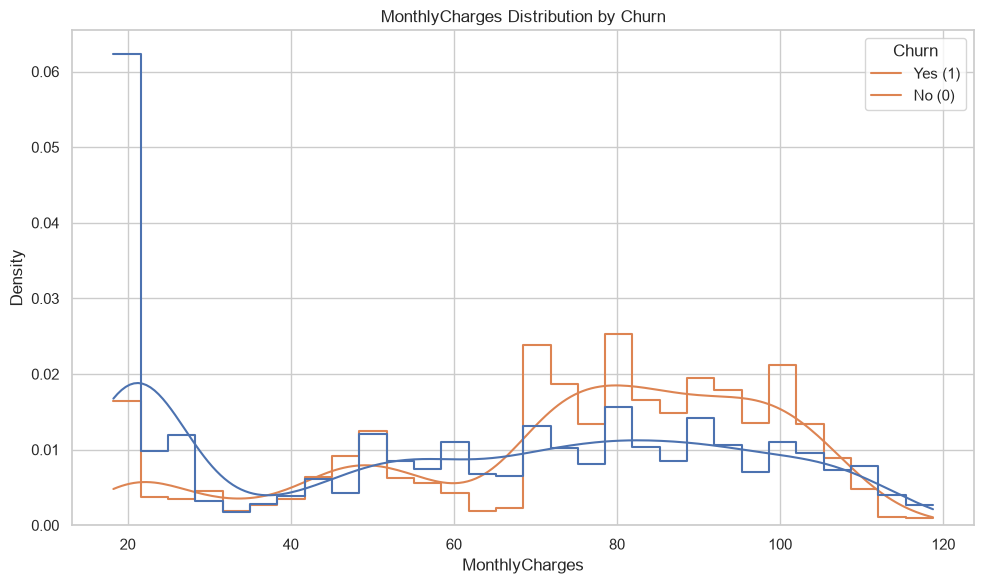

In [7]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(
    data=monthly_charges_analysis,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    kde=True,
)
plt.title("MonthlyCharges Distribution by Churn")
plt.xlabel("MonthlyCharges")
plt.ylabel("Density")
plt.legend(title="Churn", labels=["Yes (1)", "No (0)"])
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=monthly_charges_analysis,
    x="Churn_Encoded",
    y="MonthlyCharges",
    order=[0, 1],
)
plt.title("MonthlyCharges by Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("MonthlyCharges")
plt.tight_layout()
plt.show()